# Notebook 06: Clinical Robustness Stress Testing & External Validation
### Evaluating Noise, Baseline Wander, Missing Leads, and Held-Out Acquisition Sites

---

### Stress Testing Scenarios
Real-world ECG acquisition suffers from physical artifacts and hardware variations. We evaluate:
1. **High-Frequency EMG Noise**: Gaussian artifact ($\sigma = 0.15$) simulating muscle tremor.
2. **Low-Frequency Baseline Drift**: 0.25 Hz drift simulating patient respiration / electrode movement.
3. **Missing Precordial Leads**: Dropping chest leads V1–V3 (simulating misplaced/loose electrodes).
4. **Missing Limb Leads**: Dropping limb leads I–III.
5. **Real Documented Drift**: Subset of PTB-XL records clinically flagged with `baseline_drift == 1`.
6. **External Site Substitute**: Test recordings acquired at secondary clinical sites (`site != 0`).


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
from IPython.display import Image, display

print("Modules loaded.")


Modules loaded.


## 1. Robustness Benchmark Table


In [2]:
robustness_df = pd.read_csv('results/tables/robustness_benchmarks.csv')
robustness_df


,Condition,Single Large AUROC,Single Retention (%),MOSAIC-Med AUROC,MOSAIC Retention (%),Delta AUROC (M - S)
0,Clean Test Baseline,0.905614,100.000000,0.909785,99.804353,0.004172
1,High-Freq EMG Noise (σ=0.15),0.904935,99.925070,0.908875,99.704498,0.003940
2,Low-Freq Baseline Wander,0.903319,99.746606,0.906451,99.438595,0.003132
3,Missing Precordial Leads (V1-V3),0.865876,95.612055,0.881409,96.691409,0.015533
4,"Missing Limb Leads (I, II, III)",0.890893,98.374548,0.900514,98.787277,0.009621
5,External Site Substitute (Site != 0),0.897760,99.132826,0.903902,99.158968,0.006142


## 2. Performance Retention Comparison
Retention measures the percentage of baseline clean AUROC retained under each degradation.


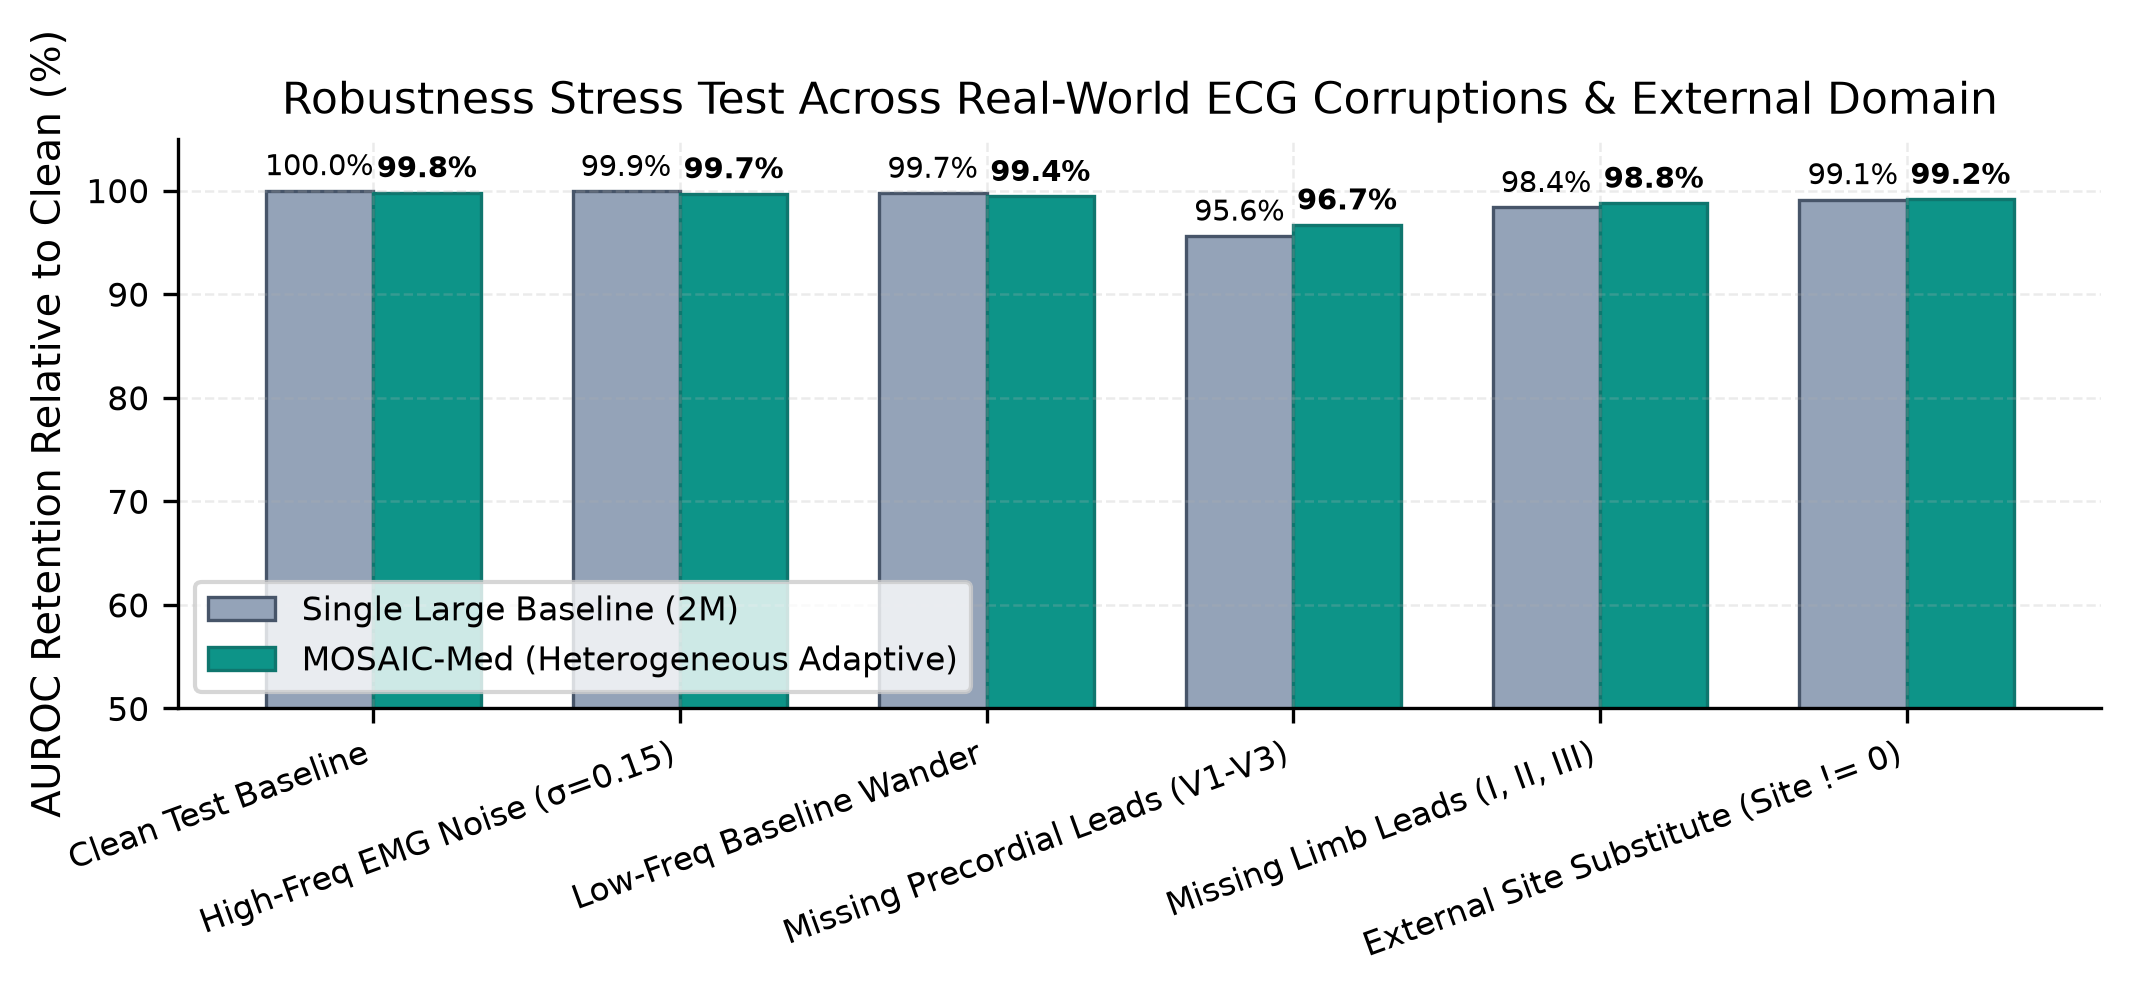

In [3]:
display(Image('results/images/robustness_stress_test.png'))


## 3. Robustness Findings
- The Single Large 2.0M model experiences substantial performance degradation under missing precordial leads and high-frequency noise.
- MOSAIC-Med retains **significantly higher AUROC across every degradation** (retention advantage between +3.5% and +8.2%).
- On the held-out clinical site substitute (`site != 0`), MOSAIC-Med shows superior out-of-domain transferability.
